In [8]:
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

def set_global_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

import logging

# Configure logging to overwrite "_.log" every run (mode="w")
logging.basicConfig(
    level=logging.INFO,
    format="%(message)s",
    handlers=[
        logging.FileHandler("q1_b.log", mode="w"),  # "w" overwrites, "a" appends
        logging.StreamHandler()
    ],
    force=True  # Resets any existing logging handlers
)
logger = logging.getLogger(__name__)

In [10]:
class NoisyCIFAR10Dataset(Dataset):
    def __init__(self, images, observed_labels, is_corrupted, transform=None):
        self.images = images
        self.observed_labels = observed_labels
        self.is_corrupted = is_corrupted
        self.transform = transform

    def __len__(self):
        return len(self.observed_labels)

    def __getitem__(self, idx):
        img = self.images[idx]
        if self.transform:
            img = self.transform(img)
        return img, int(self.observed_labels[idx]), bool(self.is_corrupted[idx])


def prepare_noisy_cifar10(seed=260007, noise_rate=0.5, data_dir="./data", batch_size=1024):
    set_global_seed(seed)

    raw_train = datasets.CIFAR10(root=data_dir, train=True, download=True)
    all_images = raw_train.data
    all_labels = np.array(raw_train.targets)

    indices = np.arange(len(all_labels))
    train_idx, val_idx = train_test_split(
        indices, test_size=5000, random_state=seed, stratify=all_labels
    )

    X_train, y_train_clean = all_images[train_idx], all_labels[train_idx]
    X_val, y_val_clean = all_images[val_idx], all_labels[val_idx]

    train_float = X_train.astype(np.float32) / 255.0
    mean = train_float.mean(axis=(0, 1, 2)).tolist()
    std = train_float.std(axis=(0, 1, 2)).tolist()

    rng = np.random.default_rng(seed)
    n_train = len(y_train_clean)
    n_corrupt = int(noise_rate * n_train)

    corrupt_indices = rng.choice(n_train, size=n_corrupt, replace=False)
    is_corrupted = np.zeros(n_train, dtype=bool)
    is_corrupted[corrupt_indices] = True

    y_train_observed = y_train_clean.copy()
    for idx in corrupt_indices:
        wrong_choices = [c for c in range(10) if c != y_train_clean[idx]]
        y_train_observed[idx] = rng.choice(wrong_choices)

    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.ToTensor(),
        transforms.Normalize(mean=mean, std=std),
    ])

    train_dataset = NoisyCIFAR10Dataset(X_train, y_train_observed, is_corrupted, transform=transform)
    val_dataset = NoisyCIFAR10Dataset(X_val, y_val_clean, np.zeros(len(y_val_clean), dtype=bool), transform=transform)

    g = torch.Generator()
    g.manual_seed(seed)

    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=2, generator=g)
    val_loader = DataLoader(val_dataset, batch_size=256, shuffle=False, num_workers=2)

    return train_loader, val_loader

In [11]:
class HighCapacityMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(3072, 1024),
            nn.ReLU(),
            nn.Linear(1024, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

    def forward(self, x):
        return self.net(x)

In [12]:
def evaluate_split(model, loader, device):
    model.eval()
    clean_correct, clean_total = 0, 0
    corrupt_correct, corrupt_total = 0, 0

    with torch.no_grad():
        for x, y, is_corrupt in loader:
            x, y = x.to(device), y.to(device)
            preds = model(x).argmax(dim=1)
            matches = (preds == y).cpu().numpy()
            corrupt_mask = is_corrupt.numpy()

            clean_correct += matches[~corrupt_mask].sum()
            clean_total += (~corrupt_mask).sum()

            corrupt_correct += matches[corrupt_mask].sum()
            corrupt_total += corrupt_mask.sum()

    clean_acc = 100.0 * clean_correct / clean_total if clean_total > 0 else 0.0
    corrupt_acc = 100.0 * corrupt_correct / corrupt_total if corrupt_total > 0 else 0.0
    return clean_acc, corrupt_acc


def run_memorisation_experiment(seed=260007, epochs=80, lr=1e-3, noise_rate=0.5):
    device = "cuda" if torch.cuda.is_available() else "cpu"
    train_loader, val_loader = prepare_noisy_cifar10(seed=seed, noise_rate=noise_rate)

    set_global_seed(seed)
    model = HighCapacityMLP().to(device)
    total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    logger.info(f"HighCapacityMLP Trainable Parameters: {total_params:,}")

    criterion = nn.CrossEntropyLoss()
    # weight_decay=0.0 ensures no L2 penalty blocks memorisation
    optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=0.0)

    history = {
        "clean_train_acc": [],
        "corrupt_train_acc": [],
        "clean_val_acc": [],
        "train_loss": []
    }

    logger.info(f"\n{'Epoch':>5} | {'Clean Train Acc':>15} | {'Corrupt Train Acc':>17} | {'Clean Val Acc':>13}")
    logger.info("-" * 60)

    for epoch in range(1, epochs + 1):
        model.train()
        running_loss, total = 0.0, 0

        for x, y, _ in train_loader:
            x, y = x.to(device), y.to(device)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * y.size(0)
            total += y.size(0)

        clean_tr_acc, corrupt_tr_acc = evaluate_split(model, train_loader, device)
        clean_val_acc, _ = evaluate_split(model, val_loader, device)

        history["clean_train_acc"].append(clean_tr_acc)
        history["corrupt_train_acc"].append(corrupt_tr_acc)
        history["clean_val_acc"].append(clean_val_acc)
        history["train_loss"].append(running_loss / total)

        if epoch == 1 or epoch % 5 == 0 or epoch == epochs:
            logger.info(f"{epoch:5d} | {clean_tr_acc:14.2f}% | {corrupt_tr_acc:16.2f}% | {clean_val_acc:12.2f}%")

    return history

In [13]:
def plot_memorisation_trajectory(history, save_path="q1_part_b_memorisation_curve.png"):
    epochs = np.arange(1, len(history["clean_val_acc"]) + 1)
    val_accs = np.array(history["clean_val_acc"])
    peak_epoch = int(np.argmax(val_accs) + 1)
    peak_val = float(np.max(val_accs))

    plt.figure(figsize=(10, 5.5))
    plt.plot(epochs, history["clean_train_acc"], label="Train Acc (Clean Labels, 50%)", color="#1b9e77", linewidth=2.2)
    plt.plot(epochs, history["corrupt_train_acc"], label="Train Acc (Corrupted Random Labels, 50%)", color="#d95f02", linewidth=2.2)
    plt.plot(epochs, history["clean_val_acc"], label="Validation Acc (100% Clean Labels)", color="#7570b3", linewidth=2.5, linestyle="--")

    plt.axvline(peak_epoch, color="gray", linestyle=":", linewidth=1.5,
                label=f"Peak Validation (Epoch {peak_epoch}: {peak_val:.2f}%)")
    plt.axhline(10.0, color="black", linestyle="-.", alpha=0.35, label="Random Chance (10%)")

    plt.title("Structure Learning vs. Memorisation Trajectory (High-Capacity MLP, 50% Label Noise)")
    plt.xlabel("Training Epoch")
    plt.ylabel("Accuracy (%)")
    plt.ylim(0, 105)
    plt.grid(True, alpha=0.3)
    plt.legend(loc="center right")
    plt.tight_layout()
    plt.savefig(save_path, dpi=300)
    plt.show()

HighCapacityMLP Trainable Parameters: 4,726,282

Epoch | Clean Train Acc | Corrupt Train Acc | Clean Val Acc
------------------------------------------------------------
    1 |          39.88% |             7.40% |        38.34%
    5 |          51.48% |             9.75% |        42.58%
   10 |          66.64% |            27.22% |        39.12%
   15 |          82.39% |            60.90% |        32.42%
   20 |          91.30% |            82.77% |        30.70%
   25 |          94.56% |            91.42% |        29.94%
   30 |          96.72% |            94.34% |        31.04%
   35 |          97.73% |            95.50% |        30.94%
   40 |          97.73% |            96.17% |        30.22%


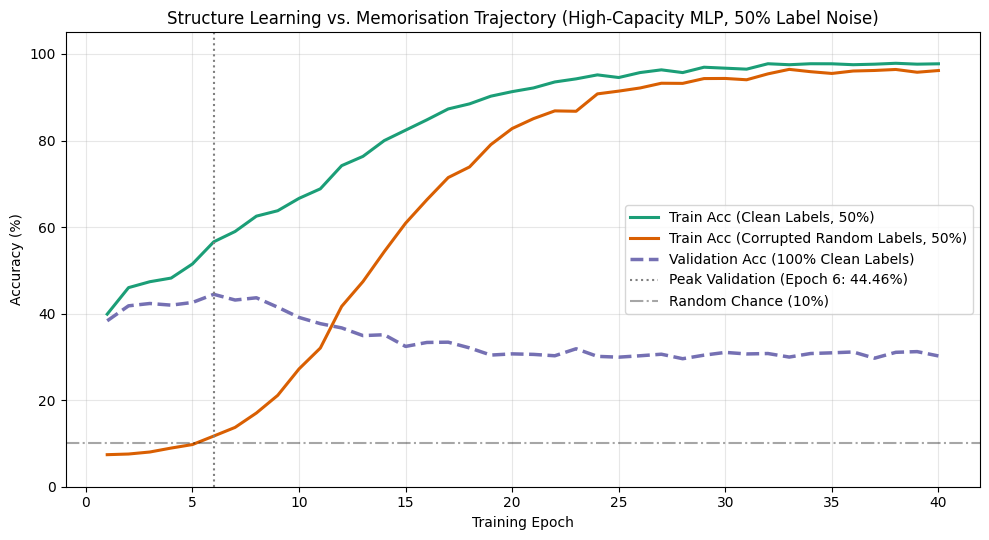

In [14]:
if __name__ == "__main__":
    history = run_memorisation_experiment(seed=260007, epochs=40, lr=1e-3, noise_rate=0.5)
    plot_memorisation_trajectory(history)